In [ ]:
# %pip install pandas scikit-learn matplotlib seaborn jupyter

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# Exercice 1 — Régression : Prédiction du tarif d’un trajet Uber
## 1. Contexte du Dataset:

Le jeu de données retenu est le **Uber Fares Dataset**, disponible publiquement sur la plateforme Kaggle.
* **Jeu de données :** Uber Fare Prediction Dataset (Kaggle).
* **Lien de la base :** [Kaggle - Uber Fares Dataset](https://kaggle.com)
* **Objectif :** Prédire le prix d’un trajet Uber (`fare_amount`) à partir de caractéristiques continues et temporelles.


## 2. Chargement et exploration du jeu de données
Nous chargeons le fichier CSV avec Pandas pour inspecter la structure initiale, identifier les types de variables et recenser la présence de valeurs manquantes afin de guider le nettoyage.

In [13]:
import pandas as pd

# Chargement du fichier
data = pd.read_csv('uber.csv')

# --- APPERÇU DES DONNÉES ---
print("="*60)
print(" 1. LES 5 PREMIÈRES LIGNES DU JEU DE DONNÉES ".center(60, "#"))
print("="*60)
print(data.head())
print("\n" + "_"*60 + "\n") # Ligne de séparation vide

# --- SECTION 2 : STRUCTURE ET TYPES ---
print("="*60)
print(" 2. INFORMATIONS SUR LES COLONNES ET TYPES ".center(60, "#"))
print("="*60)
data.info() # Remarque : .info() fait déjà un print automatique, pas besoin d'un print autour
print("\n" + "_"*60 + "\n")

# --- VALEURS MANQUANTES ---
print("="*60)
print(" 3. COMPTAGE DES VALEURS MANQUANTES (MANQUENT DANS LE CSV) ".center(60, "#"))
print("="*60)
print(data.isnull().sum())
print("="*60)



####### 1. LES 5 PREMIÈRES LIGNES DU JEU DE DONNÉES ########
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2      

## 3. Nettoyage et préparation
Pour assainir le jeu de données avant l'apprentissage, nous appliquons les règles métiers suivantes :
1. Suppression des valeurs manquantes.
2. Élimination des tarifs négatifs ou nuls (`fare_amount > 0`).
3. Extraction de caractéristiques temporelles utiles (`hour` et `day_of_week`) à partir de la date de prise en charge.


In [14]:
import pandas as pd

# --- 1. NETTOYAGE DES DONNÉES ---
print("="*60)
print(" 1. SUPPRESSION DES VALEURS MANQUANTES ".center(60, "#"))
print("="*60)
# Avant nettoyage
print(f"Lignes avant suppression : {len(data)}")
data = data.dropna()
# Après nettoyage
print(f"Lignes après suppression : {len(data)}")
print("\n" + "_"*60 + "\n")


# --- 2. TRAITEMENT DES VALEURS ABERRANTES ---
print("="*60)
print(" 2. FILTRAGE DES TARIFS POSITIFS ".center(60, "#"))
print("="*60)
# Correction : on utilise 'fare_amount' qui est le vrai nom de la colonne en question
data = data[data['fare_amount'] > 0]
print("Filtrage terminé. Les tarifs négatifs ou nuls ont été retirés.")
print("\n" + "_"*60 + "\n")


# --- 3. CRÉATION DES VARIABLES DÉRIVÉES ---
print("="*60)
print(" 3. EXTRACTION DE L'HEURE ET DU JOUR ".center(60, "#"))
print("="*60)
# Conversion de la colonne en type Date/Heure
data['pickup_datetime'] = pd.to_datetime(data['pickup_datetime'])

# Extraction des nouvelles caractéristiques
data['hour'] = data['pickup_datetime'].dt.hour
data['day_of_week'] = data['pickup_datetime'].dt.dayofweek

print("Nouvelles colonnes 'hour' et 'day_of_week' créées avec succès.")
print("="*60)

# Affichage final pour vérifier visuellement le résultat
data.head()


########## 1. SUPPRESSION DES VALEURS MANQUANTES ###########
Lignes avant suppression : 200000
Lignes après suppression : 199999

____________________________________________________________

############# 2. FILTRAGE DES TARIFS POSITIFS ##############
Filtrage terminé. Les tarifs négatifs ou nuls ont été retirés.

____________________________________________________________

########### 3. EXTRACTION DE L'HEURE ET DU JOUR ############
Nouvelles colonnes 'hour' et 'day_of_week' créées avec succès.


,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,hour,day_of_week
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,19,3
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,20,4
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,21,0
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,8,4
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,17,3


## 4. Feature Engineering et Séparation des données 
1. **Calcul de la distance :** À partir des coordonnées géographiques (latitude/longitude), nous implémentons la formule de Haversine  pour générer la variable explicative `distance` en kilomètres.Contrairement à la géométrie classique (comme la formule d'Euclide) qui calcule une distance sur un plan plat, la formule de Haversine prend en compte la courbure de la Terre en la modélisant comme une sphère.C'est un excellent compromis entre précision géopolitique et rapidité de calcul pour notre modèle.
2. **Découpage Train/Test :** Nous isolons nos caractéristiques (`distance`, `hour`, `day_of_week`) de notre variable cible (`fare_amount`). Les données sont divisées aléatoirement avec un ratio de 80% pour l'entraînement et 20% pour le test.


In [15]:
from sklearn.model_selection import train_test_split
import numpy as np

# --- 1. CALCUL DE LA DISTANCE À PARTIR DES COORDONNÉES GÉOGRAPHIQUES ---
print("="*60)
print(" 1. CALCUL DE LA COLONNE DISTANCE (EN KM) ".center(60, "#"))
print("="*60)

# Formule mathématique pour calculer la distance sur Terre
def calculer_distance(lat1, lon1, lat2, lon2):
    rayon_terre = 6371.0 # Rayon moyen de la Terre en kilomètres
    
    lat1_rad, lon1_rad = np.radians(lat1), np.radians(lon1)
    lat2_rad, lon2_rad = np.radians(lat2), np.radians(lon2)
    
    dlat = lat2_rad - lat1_rad
    dlon = lon2_rad - lon1_rad
    
    a = np.sin(dlat / 2)**2 + np.cos(lat1_rad) * np.cos(lat2_rad) * np.sin(dlon / 2)**2
    c = 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a))
    
    return rayon_terre * c

# Ajout de la colonne distance dans nos données
data['distance'] = calculer_distance(
    data['pickup_latitude'], data['pickup_longitude'], 
    data['dropoff_latitude'], data['dropoff_longitude']
)

print("La colonne 'distance' a été calculée et ajoutée avec succès.")
print(data[['pickup_latitude', 'pickup_longitude', 'distance']].head())
print("\n" + "_"*60 + "\n")


# --- 2. SÉLECTION DES CARACTÉRISTIQUES (X) ET DE LA CIBLE (y) ---
print("="*60)
print(" 2. CRÉATION DES MATRICES X ET y ".center(60, "#"))
print("="*60)

X = data[['distance', 'hour', 'day_of_week']]
y = data['fare_amount']

print("Matrice des caractéristiques (X) et vecteur cible (y) créés.")
print(f"Dimensions de X : {X.shape}")
print(f"Dimensions de y : {y.shape}")
print("\n" + "_"*60 + "\n")


# --- 3. DIVISION EN DONNÉES D'ENTRAÎNEMENT ET DE TEST ---
print("="*60)
print(" 3. SÉPARATION DES DONNÉES (80% TRAIN / 20% TEST) ".center(60, "#"))
print("="*60)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Séparation effectuée avec succès :")
print(f" -> Échantillon d'entraînement (X_train) : {X_train.shape[0]} lignes")
print(f" -> Échantillon de test (X_test)         : {X_test.shape[0]} lignes")
print("="*60)


######### 1. CALCUL DE LA COLONNE DISTANCE (EN KM) #########
La colonne 'distance' a été calculée et ajoutée avec succès.
   pickup_latitude  pickup_longitude  distance
0        40.738354        -73.999817  1.683323
1        40.728225        -73.994355  2.457590
2        40.740770        -74.005043  5.036377
3        40.790844        -73.976124  1.661683
4        40.744085        -73.925023  4.475450

____________________________________________________________

############# 2. CRÉATION DES MATRICES X ET y ##############
Matrice des caractéristiques (X) et vecteur cible (y) créés.
Dimensions de X : (199977, 3)
Dimensions de y : (199977,)

____________________________________________________________

##### 3. SÉPARATION DES DONNÉES (80% TRAIN / 20% TEST) #####
Séparation effectuée avec succès :
 -> Échantillon d'entraînement (X_train) : 159981 lignes
 -> Échantillon de test (X_test)         : 39996 lignes


## 5. Entraînement du modèle linéaire
Nous instancions un premier algorithme de base : la **Régression Linéaire** (`LinearRegression`). La méthode `.fit()` calcule les coefficients optimaux (poids w et biais b) en minimisant l'erreur quadratique moyenne sur l'échantillon d'entraînement.


In [16]:
from sklearn.linear_model import LinearRegression

# --- 1. APPRENTISSAGE DU MODÈLE ---
print("="*60)
print(" 1. ENTRAÎNEMENT DE LA RÉGRESSION LINÉAIRE ".center(60, "#"))
print("="*60)

# Initialisation du modèle
lr = LinearRegression()

# Entraînement sur les données (Calcul des poids mathématiques)
lr.fit(X_train, y_train)

print("Le modèle de Régression Linéaire a été entraîné avec succès.")
print(f" -> Poids des variables (Coefficients) : {lr.coef_}")
print(f" -> Biais du modèle (Intercept)        : {lr.intercept_}")
print("\n" + "_"*60 + "\n")


# --- 2. PRÉDICTION SUR LES DONNÉES INCONNUES ---
print("="*60)
print(" 2. GÉNÉRATION DES PRÉDICTIONS DE TEST ".center(60, "#"))
print("="*60)

# Prédiction sur l'échantillon de test
y_pred = lr.predict(X_test)

print("Prédictions terminées.")
print(f"Nombre de tarifs Uber prédits : {len(y_pred)}")
print(f" -> Exemple de tarif réel   : {y_test.iloc[0]:.2f} $")
print(f" -> Exemple de tarif prédit : {y_pred[0]:.2f} $")
print("="*60)


######## 1. ENTRAÎNEMENT DE LA RÉGRESSION LINÉAIRE #########
Le modèle de Régression Linéaire a été entraîné avec succès.
 -> Poids des variables (Coefficients) : [ 0.00065973 -0.02876221  0.03022581]
 -> Biais du modèle (Intercept)        : 11.640263686054976

____________________________________________________________

########## 2. GÉNÉRATION DES PRÉDICTIONS DE TEST ###########
Prédictions terminées.
Nombre de tarifs Uber prédits : 39996
 -> Exemple de tarif réel   : 5.70 $
 -> Exemple de tarif prédit : 11.79 $


## 6. Évaluation des performances du modèle linéaire
Pour mesurer l'erreur de notre modèle continu, nous calculons les métriques de régression standards :
* **MAE** (Erreur Absolue Moyenne) : robuste aux valeurs extrêmes.
* **RMSE** (Racine de l'Erreur Quadratique Moyenne) : pénalise fortement les grandes erreurs.
* **$R^2$** (Coefficient de détermination) : mesure la proportion de la variance expliquée (proche de 1 = prédiction parfaite).


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# --- CALCUL DES MÉTRIQUES D'ÉVALUATION ---
print("="*60)
print(" ÉVALUATION DES PERFORMANCES DU MODÈLE ".center(60, "#"))
print("="*60)

# Calcul des scores
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Affichage des résultats
print(f" -> MAE (Erreur Absolue Moyenne) : {mae:.4f} $")
print(f" -> RMSE (Erreur Quadratique Moyenne) : {rmse:.4f} $")
print(f" -> R² (Coefficient de Détermination) : {r2:.4f}")
print("="*60)

# - MAE : En moyenne, le modèle se trompe de {mae:.2f} $ par rapport au vrai prix.
# - R² : Si la valeur est proche de 0 (ou négative), le modèle linéaire a du mal à capter les règles des données.


########## ÉVALUATION DES PERFORMANCES DU MODÈLE ###########
 -> MAE (Erreur Absolue Moyenne) : 6.0246 $
 -> RMSE (Erreur Quadratique Moyenne) : 9.6360 $
 -> R² (Coefficient de Détermination) : 0.0015


## 7. Amélioration avec l'algorithme Random Forest
Les relations réelles entre la distance et le tarif d'un trajet étant souvent non linéaires, le modèle linéaire affiche des performances très limitées (R² proche de 0). Nous basculons sur un modèle d'ensemble non linéaire : le **`RandomForestRegressor`** (100 arbres de décision) afin de capturer la complexité des données.


In [18]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# --- 1. APPRENTISSAGE DU MODÈLE RANDOM FOREST ---
print("="*60)
print(" 1. ENTRAÎNEMENT DU MODÈLE RANDOM FOREST ".center(60, "#"))
print("="*60)
print("Veuillez patienter, l'entraînement peut prendre quelques secondes...")

# Initialisation du modèle avec 100 arbres
rf = RandomForestRegressor(n_estimators=100, random_state=42)

# Entraînement du modèle
rf.fit(X_train, y_train)

print("Le modèle Random Forest a été entraîné avec succès.")
print("\n" + "_"*60 + "\n")


# --- 2. PRÉDICTION ET ÉVALUATION DES PERFORMANCES ---
print("="*60)
print(" 2. ÉVALUATION DES PERFORMANCES (RANDOM FOREST) ".center(60, "#"))
print("="*60)

# Prédiction sur l'échantillon de test
y_pred_rf = rf.predict(X_test)

# Calcul des nouveaux scores
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

# Affichage des résultats
print(f" -> MAE  (Random Forest) : {mae_rf:.4f} $")
print(f" -> RMSE (Random Forest) : {rmse_rf:.4f} $")
print(f" -> R²   (Random Forest) : {r2_rf:.4f}")
print("="*60)

#  On Compare ces valeurs avec celles de la Régression Linéaire (Étape 5)
# Si le MAE a diminué et le R² a augmenté, le Random Forest a bien amélioré les prédictions 


######### 1. ENTRAÎNEMENT DU MODÈLE RANDOM FOREST ##########
Veuillez patienter, l'entraînement peut prendre quelques secondes...
Le modèle Random Forest a été entraîné avec succès.

____________________________________________________________

###### 2. ÉVALUATION DES PERFORMANCES (RANDOM FOREST) ######
 -> MAE  (Random Forest) : 2.6756 $
 -> RMSE (Random Forest) : 5.2447 $
 -> R²   (Random Forest) : 0.7042


## 8. Visualisation des performances
Nous traçons le nuage de points mettant en confrontation les valeurs réelles du dataset de test face aux valeurs prédites par notre forêt aléatoire. La ligne en pointillés rouge représente la prédiction idéale parfaite.

########## GÉNÉRATION DU GRAPHIQUE DE PERFORMANCE ##########


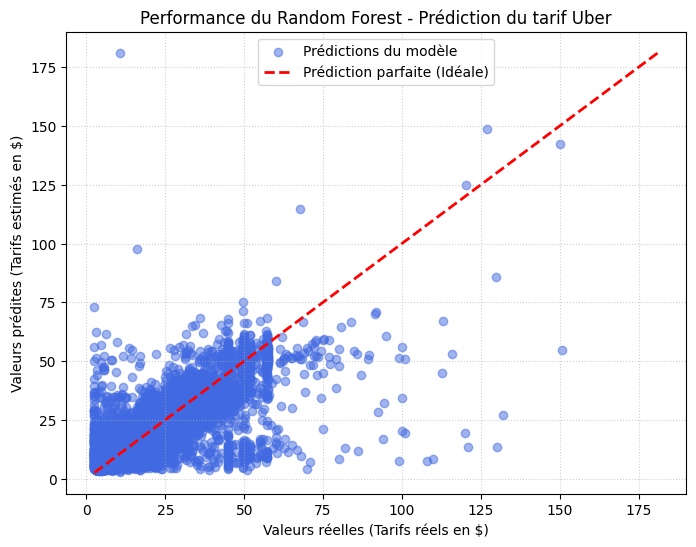

Graphique généré avec succès.


In [19]:
import matplotlib.pyplot as plt

# --- VISUALISATION DES PRÉDICTIONS ---
print("="*60)
print(" GÉNÉRATION DU GRAPHIQUE DE PERFORMANCE ".center(60, "#"))
print("="*60)

# Définition de la taille de la figure
plt.figure(figsize=(8, 6))

# Tracé du nuage de points (Vrai tarif vs Tarif prédit)
plt.scatter(y_test, y_pred_rf, alpha=0.5, color='royalblue', label='Prédictions du modèle')

# Tracé de la ligne idéale (où prédiction = réalité)
limites = [min(y_test.min(), y_pred_rf.min()), max(y_test.max(), y_pred_rf.max())]
plt.plot(limites, limites, color='red', linestyle='--', linewidth=2, label='Prédiction parfaite (Idéale)')

# Habillage du graphique
plt.xlabel('Valeurs réelles (Tarifs réels en $)')
plt.ylabel('Valeurs prédites (Tarifs estimés en $)')
plt.title('Performance du Random Forest - Prédiction du tarif Uber')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)

# Affichage du graphique directement dans le notebook
plt.show()

print("="*60)
print("Graphique généré avec succès.")
print("="*60)


## Conclusion :

L'analyse comparative des métriques d'évaluation met en évidence une différence de performance radicale :
* **La Régression Linéaire** échoue avec un $R^2$ de **0.0015**, ce qui indique qu'elle n'explique absolument pas la variance des prix et se montre incapable de modéliser ce problème.
* **Le Random Forest Regressor** enregistre une amélioration spectaculaire en atteignant un score $R^2$ de **0.7042**. Sa métrique d'erreur absolue moyenne (**MAE**) descend à **2.67 $**, signifiant qu'en moyenne, l'estimation de la forêt ne s'éloigne que de 2.67 dollars du coût réel du trajet Uber.

**Bilan critique :** Le modèle à retenir est le **Random Forest**. La tarification d'un trajet intègre des composantes non linéaires évidentes (tarifs minimums de prise en charge, majorations selon les heures de pointe, trafic urbain non proportionnel à la distance géographique). Les modèles basés sur des arbres de décision capturent nativement ces segmentations logiques, là où une simple droite de régression linéaire échoue.
